# Dynamical friction in `gala`: the LMC orbit around the Milky Way

In this tutorial we build, from scratch and in this notebook, everything needed to compute the orbit of the
Large Magellanic Cloud (LMC) around the Milky Way (MW) including **dynamical friction (DF)**:

1. **Potentials**: a multi-component MW and the LMC as a Hernquist sphere.
2. **Initial conditions**: the present-day position and velocity of the LMC.
3. **The Chandrasekhar dynamical friction formula**: a walk through each term and what it means.
4. **Adding DF to `gala`**: `gala` integrators accept *any* Python function `F(t, w, *args) -> dw/dt`, so we can add
   DF on top of the gravitational accelerations. We test it by integrating the LMC for different DF parameters,
   first as a **test particle** in a static MW and then in a live MW + LMC system with **`gd.DirectNBody`**.
5. **Inertial vs. non-inertial frames**: a test particle on a circular polar orbit, integrated for 4 Gyr in the
   inertial frame and in the (accelerated) frame of the MW disk.

The LMC orbits are integrated **backwards in time** from the present day (Step 5 then goes forwards along them).

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

import astropy.units as u
from astropy.constants import G as G_const

import gala.potential as gp
import gala.dynamics as gd
import gala.integrate as gi
from gala.units import galactic

# G in the gala `galactic` unit system: kpc^3 / (Msun Myr^2)
G_gal = G_const.to_value(u.kpc**3 / u.Msun / u.Myr**2)
print(f'G = {G_gal:.6e} kpc^3 / (Msun Myr^2)')
print(galactic)

G = 4.498502e-12 kpc^3 / (Msun Myr^2)
UnitSystem (kpc, Myr, solMass, rad)


## 1. Potentials

### 1a. The Milky Way

The MW is a sum of four components. All of them use the `galactic` unit system (kpc, Myr, $M_\odot$, rad):

| component | model | parameters |
|---|---|---|
| disk | Miyamoto–Nagai fit to an exponential disk (`MN3ExponentialDiskPotential`) | $M_d = 4.77\times10^{10}\,M_\odot$, $h_R = 2.6$ kpc, $h_z = 0.3$ kpc |
| bulge | Hernquist | $M_b = 5\times10^{9}\,M_\odot$, $c = 1$ kpc |
| nucleus | Hernquist | $M_n = 1.81\times10^{9}\,M_\odot$, $c = 0.069$ kpc |
| dark matter halo | NFW (Lee & Suto triaxial form; $a=b=c=1$ is spherical) | $v_c = 171.6$ km/s, $r_s = 15.6$ kpc |

Here `a, b, c` are the halo axis ratios, and we keep the halo spherical.

v_c(8.1 kpc) = 229.4 km/s,  V_max = 230.1 km / s at r = 7 kpc


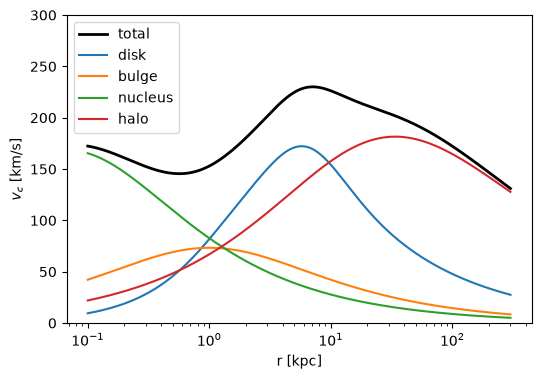

In [2]:
def mw_potential(a=1, b=1, c=1):
    mwpot = gp.CCompositePotential()
    mwpot["disk"] = gp.MN3ExponentialDiskPotential(units=galactic, m=4.7717e10 * u.Msun,
                                                   h_R=2.6 * u.kpc, h_z=0.3 * u.kpc)
    mwpot["bulge"] = gp.HernquistPotential(units=galactic, m=5e9 * u.Msun, c=1.0 * u.kpc)
    mwpot["nucleus"] = gp.HernquistPotential(units=galactic, m=1.8142e9 * u.Msun, c=0.0688867 * u.kpc)
    mwpot["halo"] = gp.LeeSutoTriaxialNFWPotential(units=galactic, v_c=171.6 * u.km / u.s,
                                                   r_s=15.626 * u.kpc, a=a, b=b, c=c)
    return mwpot

mwpot = mw_potential()

r = np.logspace(-1, np.log10(300), 400)
xyz = np.array([r, np.zeros_like(r), np.zeros_like(r)]) * u.kpc

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r, mwpot.circular_velocity(xyz).to(u.km / u.s), c='k', lw=2, label='total')
for name, pot in mwpot.items():
    ax.plot(r, pot.circular_velocity(xyz).to(u.km / u.s), label=name)
ax.set_xscale('log'); ax.set_ylim(0, 300)
ax.set_xlabel('r [kpc]'); ax.set_ylabel(r'$v_c$ [km/s]'); ax.legend()

vc_mw = mwpot.circular_velocity(xyz).to(u.km / u.s)
print(f'v_c(8.1 kpc) = {np.interp(8.1, r, vc_mw.value):.1f} km/s,  V_max = {vc_mw.max():.1f} '
      f'at r = {r[vc_mw.argmax()]:.0f} kpc')

### 1b. The LMC

The LMC is a Hernquist sphere,

$$
\Phi_{\rm LMC}(r) = -\frac{G\,M_{\rm LMC}}{r + a_{\rm LMC}},
$$

with $M_{\rm LMC} = 1.8\times10^{11}\,M_\odot$ and a scale radius $a_{\rm LMC} = 20$ kpc. The Hernquist profile has a finite
total mass, so $M_{\rm LMC}$ is also the mass we use for the satellite in the DF formula.

In [3]:
def lmc_potential(mlmc, clmc):
    return gp.HernquistPotential(units=galactic, m=mlmc * u.Msun, c=clmc * u.kpc)

M_lmc = 1.8e11   # Msun
a_lmc = 20.0     # kpc
lmcpot = lmc_potential(M_lmc, a_lmc)

print(f'M_LMC / M_MW(<300 kpc) ~ {M_lmc / (vc_mw[-1].to_value(u.kpc/u.Myr)**2 * 300 / G_gal):.2f}')

M_LMC / M_MW(<300 kpc) ~ 0.15


## 2. Initial conditions

We integrate in a Galactocentric Cartesian frame centered on the present-day MW, with the MW at rest at the origin.
The LMC phase-space coordinates are

$$
\mathbf{x}_{\rm LMC} = (-1.1,\,-41.1,\,-27.9)\ {\rm kpc}, \qquad
\mathbf{v}_{\rm LMC} = (-57,\,-226,\,221)\ {\rm km/s}.
$$

These come from the observed position (distance $\simeq 50$ kpc) and proper motion of the LMC
(Kallivayalil et al. 2013), converted to Galactocentric coordinates. They are the values used in
Garavito-Camargo et al. (2019). To explore how the orbit depends on the observations, you can replace them with your own
conversion (e.g. with `astropy.coordinates.Galactocentric`).

In [4]:
wMW = gd.PhaseSpacePosition(pos=[0, 0, 0] * u.kpc, vel=[0, 0, 0] * u.km / u.s)
wLMC = gd.PhaseSpacePosition(pos=[-1.1, -41.1, -27.9] * u.kpc, vel=[-57., -226., 221.] * u.km / u.s)

# The MW and the LMC as a single two-particle phase-space object: column 0 = MW, column 1 = LMC
w0_mwlmc = gd.combine((wMW, wLMC))

x0, v0 = wLMC.xyz, wLMC.v_xyz
r0 = np.linalg.norm(x0.to_value(u.kpc)) * u.kpc
v_tot = np.linalg.norm(v0.to_value(u.km / u.s)) * u.km / u.s
v_r = (np.dot(x0.value, v0.to_value(u.km / u.s)) / r0.value) * u.km / u.s
v_t = np.sqrt(v_tot**2 - v_r**2)
vc_at_r0 = mwpot.circular_velocity(x0)

print(f'r_LMC   = {r0:.1f}')
print(f'|v|     = {v_tot:.1f}   (v_r = {v_r:.1f}, v_t = {v_t:.1f})')
print(f'v_c(r_LMC) = {vc_at_r0[0].to(u.km/u.s):.1f}  ->  the LMC is moving ~{v_tot / vc_at_r0[0].to(u.km/u.s):.1f}x faster than a circular orbit')

r_LMC   = 49.7 kpc
|v|     = 321.2 km / s   (v_r = 64.1 km / s, v_t = 314.7 km / s)
v_c(r_LMC) = 192.8 km / s  ->  the LMC is moving ~1.7x faster than a circular orbit


## 3. Chandrasekhar dynamical friction

A satellite of mass $M_{\rm sat}$ moving with velocity $\mathbf{v}$ (relative to the host) through a
background of density $\rho(r)$ with an isotropic Maxwellian velocity distribution of dispersion $\sigma(r)$
feels a drag (Binney & Tremaine 2008, Eq. 8.7):

$$
\boxed{\;
\mathbf{a}_{\rm DF} = -\frac{4\pi G^2 M_{\rm sat}\,\rho(r)\,\ln\Lambda}{v^3}
\left[\mathrm{erf}(X) - \frac{2X}{\sqrt{\pi}}e^{-X^2}\right]\mathbf{v},
\qquad X = \frac{v}{\sqrt{2}\,\sigma(r)}\;}
$$

**What each term means**

| term | meaning |
|---|---|
| $\mathbf{a}_{\rm DF}\parallel -\mathbf{v}$ | the force is a *drag*: it always points against the velocity of the satellite relative to the host. |
| $G^2 M_{\rm sat}$ | the satellite's gravitational pull creates an overdensity wake behind it. The force on the satellite is $\propto G M_{\rm sat}\times(G M_{\rm sat}\rho)$, i.e. $\propto M_{\rm sat}^2$, so the *acceleration* is $\propto M_{\rm sat}$. Heavier satellites sink faster. |
| $\rho(r)$ | the local density of the host. More particles to scatter off means more drag. |
| $\ln\Lambda$ | the **Coulomb logarithm**: it comes from integrating encounters over impact parameters between $b_{\min}$ and $b_{\max}$, $\Lambda = b_{\max}/b_{\min}$. It is not derived from first principles for an extended, non-uniform halo, so it is a *fitted* quantity (here: Hashimoto et al. 2003 or van der Marel et al. 2012). |
| $1/v^3 \times \mathbf{v}$ | a factor $1/v^2$ in the magnitude: fast satellites have shorter encounters and so are slowed down less efficiently. |
| $\mathrm{erf}(X) - \frac{2X}{\sqrt\pi}e^{-X^2}$ | the fraction of host particles that move *slower* than the satellite, weighted by the Maxwellian. Only these particles contribute to the drag (the faster ones do not). It tends to $1$ for $v\gg\sigma$ and goes as $X^3$ for $v\ll\sigma$. |
| $X = v/(\sqrt2\sigma)$ | the satellite speed in units of the host velocity dispersion. |

We need three ingredients from the host: $\rho(r)$, $\sigma(r)$ and $\ln\Lambda$. Following Patel et al. (2017, 2020):

| ingredient | where it comes from |
|---|---|
| $\rho(r)$ | `host_potential.density(x)`, straight from the `gala` potential (total MW, evaluated at the LMC position) |
| $\sigma(r)$ | Zentner & Bullock (2003) fit for an isotropic NFW halo, scaled by $V_{\max}$ and $r_s$ |
| $\ln\Lambda$ | Hashimoto et al. (2003) or van der Marel et al. (2012) |

### 3a. Density

We evaluate the density of the MW along the line from the Galactic center through the present-day LMC position.

rho(LMC today) = 2.081e+05 solMass / kpc3


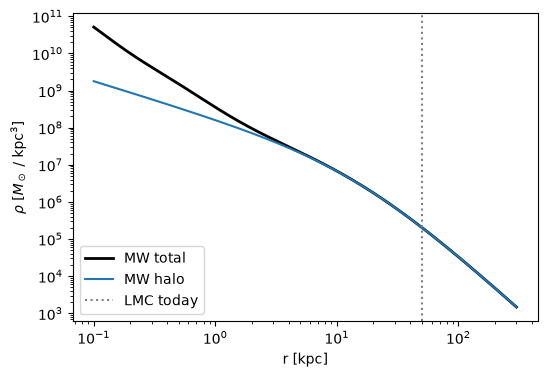

In [5]:
rhat = x0.to_value(u.kpc) / r0.value               # unit vector towards the LMC
xline = rhat[:, None] * r[None, :] * u.kpc          # (3, N) positions along that direction

rho_tot = mwpot.density(xline).to(u.Msun / u.kpc**3)
rho_halo = mwpot['halo'].density(xline).to(u.Msun / u.kpc**3)
rho_lmc_pos = mwpot.density(x0).to(u.Msun / u.kpc**3)

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(r, rho_tot, c='k', lw=2, label='MW total')
ax.loglog(r, rho_halo, label='MW halo')
ax.axvline(r0.value, c='gray', ls=':', label='LMC today')
ax.set_xlabel('r [kpc]'); ax.set_ylabel(r'$\rho$ [$M_\odot$ / kpc$^3$]'); ax.legend()
print(f'rho(LMC today) = {rho_lmc_pos[0]:.3e}')

### 3b. Velocity dispersion

The DF formula needs $\sigma(r)$ of the host, which is not an output of the `gala` potential. We use the Zentner & Bullock (2003, Eq. 6)
approximation for an isotropic NFW halo,

$$
\sigma(r) = V_{\max}\,\frac{1.4393\,x^{0.354}}{1 + 1.1756\,x^{0.725}}, \qquad x = r/r_s,
$$

where $V_{\max}$ is the maximum circular velocity and $r_s$ the scale radius.
We take $V_{\max}$ from the total MW circular velocity curve and $r_s$ from the halo.

**Units**: the formula is unit-agnostic, so $\sigma$ comes out in the same units as $V_{\max}$.
In the integration $v$ is in kpc/Myr, so $X = v/(\sqrt{2}\sigma)$ is only correct if we give $V_{\max}$ in **kpc/Myr** too.

V_max = 230.1 km / s = 0.2353 kpc / Myr,  r_s = 15.626 kpc
sigma(r_LMC) = 134.1 km / s


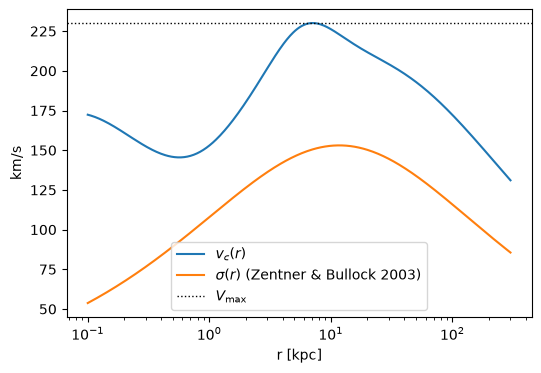

In [6]:
def sigma_NFW(vmax, rs, r):
    # Zentner & Bullock (2003) isotropic NFW dispersion; returned in the units of vmax
    x = r / rs
    return vmax * 1.4393 * x**0.354 / (1.0 + 1.1756 * x**0.725)

host_vmax = vc_mw.max().to(u.kpc / u.Myr)            # kpc/Myr, to match the integration units
host_rs = mwpot.parameters['halo']['r_s']             # kpc

sigma = sigma_NFW(host_vmax, host_rs, r * u.kpc).to(u.km / u.s)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r, vc_mw, label=r'$v_c(r)$')
ax.plot(r, sigma, label=r'$\sigma(r)$ (Zentner & Bullock 2003)')
ax.axhline(vc_mw.max().value, c='k', ls=':', lw=1, label=r'$V_{\max}$')
ax.set_xscale('log'); ax.set_xlabel('r [kpc]'); ax.set_ylabel('km/s'); ax.legend()
print(f'V_max = {vc_mw.max():.1f} = {host_vmax:.4f},  r_s = {host_rs}')
print(f'sigma(r_LMC) = {sigma_NFW(host_vmax, host_rs, r0).to(u.km/u.s):.1f}')

### 3c. The velocity factor

The bracket $f(X)=\mathrm{erf}(X) - \frac{2X}{\sqrt\pi}e^{-X^2}$ is the fraction of host particles slower than the satellite.
At the LMC's present position its speed relative to the MW is $\sim 320$ km/s while $\sigma\sim 130$ km/s, so $X \approx 1.7$ and
$f \approx 0.9$, already close to its asymptotic value of 1.

X_LMC = 1.69,  f(X_LMC) = 0.875


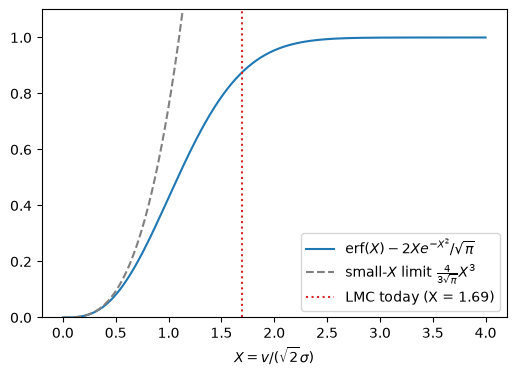

In [7]:
def velocity_factor(X):
    return erf(X) - 2 * X / np.sqrt(np.pi) * np.exp(-X**2)

X_lmc = (v_tot.to(u.kpc / u.Myr) / (np.sqrt(2) * sigma_NFW(host_vmax, host_rs, r0))).decompose().value

X = np.linspace(0, 4, 300)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(X, velocity_factor(X), label=r'$\mathrm{erf}(X) - 2X e^{-X^2}/\sqrt{\pi}$')
ax.plot(X, X**3 * 4 / (3 * np.sqrt(np.pi)), ls='--', c='gray', label=r'small-$X$ limit $\frac{4}{3\sqrt{\pi}}X^3$')
ax.axvline(X_lmc, c='C3', ls=':', label=f'LMC today (X = {X_lmc:.2f})')
ax.set_ylim(0, 1.1); ax.set_xlabel(r'$X = v/(\sqrt{2}\sigma)$'); ax.legend()
print(f'X_LMC = {X_lmc:.2f},  f(X_LMC) = {velocity_factor(X_lmc):.3f}')

### 3d. The Coulomb logarithm

We parameterize it with $[L, C, a, \alpha, \text{form}]$:

* **Hashimoto** (`'Hashimoto'`): $\ln\Lambda = \alpha \ln\left(r / 1.4a\right)$
* **van der Marel** (`'VdM'`): $\ln\Lambda = \max\left[L, \ln\left(r / Ca\right)^{\alpha}\right]$

Here $r$ is the distance of the satellite to the host center and $a$ is the satellite (Hernquist) scale length, so
$C a$ plays the role of $b_{\min}$ and $r$ that of $b_{\max}$. With $L=0$, $\alpha=1$ and $C=1.4$ the two forms are
identical. Typical values (van der Marel et al. 2012):

* equal-mass mergers: $L=0.02$, $C=0.17$, $\alpha=0.15$,
* 1:10 mass ratio (about right for the MW–LMC): $L=0$, $C=1.22$, $\alpha=1$.

The floor $L$ matters at small radii: below $r = Ca$ the logarithm is negative, which would make DF *accelerate* the satellite.
We also floor the Hashimoto form at zero for the same reason, and where $\ln(r/Ca)<0$ in the VdM form we use $L$ directly
(a negative number cannot be raised to a fractional power $\alpha$).

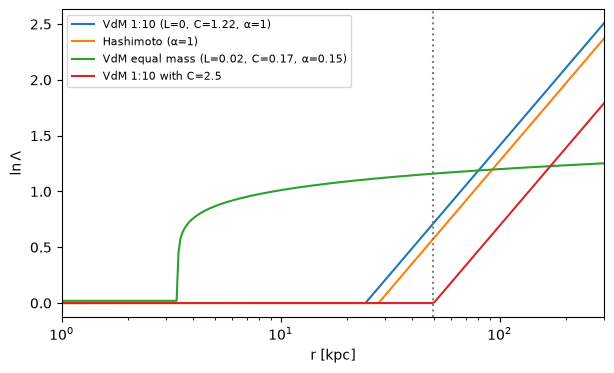

In [8]:
def ln_Lambda(r, L=0.0, C=1.22, a=20.0, alpha=1.0, form='VdM'):
    # r and a in the same units (kpc)
    if form == 'Hashimoto':
        return np.maximum(0.0, alpha * np.log(r / (1.4 * a)))
    elif form == 'VdM':
        arg = np.log(r / (C * a))
        return np.maximum(L, np.where(arg > 0, np.abs(arg)**alpha, 0.0))
    raise ValueError("form must be 'Hashimoto' or 'VdM'")

lnL_params = {
    'VdM 1:10 (L=0, C=1.22, α=1)':          dict(L=0.0,  C=1.22, alpha=1.0,  form='VdM'),
    'Hashimoto (α=1)':                      dict(alpha=1.0, form='Hashimoto'),
    'VdM equal mass (L=0.02, C=0.17, α=0.15)': dict(L=0.02, C=0.17, alpha=0.15, form='VdM'),
    'VdM 1:10 with C=2.5':                  dict(L=0.0,  C=2.5,  alpha=1.0,  form='VdM'),
}

fig, ax = plt.subplots(figsize=(7, 4))
for label, p in lnL_params.items():
    ax.plot(r, ln_Lambda(r, a=a_lmc, **p), label=label)
ax.axvline(r0.value, c='gray', ls=':')
ax.set_xscale('log'); ax.set_xlim(1, 300)
ax.set_xlabel('r [kpc]'); ax.set_ylabel(r'$\ln\Lambda$'); ax.legend(fontsize=8)

### 3e. Putting it together: `df_acceleration`

The function takes the position and velocity of the satellite **relative to the host**, so it stays valid when the MW moves
(live MW + LMC). It returns the acceleration in kpc/Myr$^2$, ready to be added to $d\mathbf{v}/dt$.

In [9]:
def df_acceleration(x_rel, v_rel, Msat, host_potential, host_vmax, host_rs, lnL_kwargs, return_terms=False):
    '''Chandrasekhar dynamical friction acceleration on a satellite (Binney & Tremaine 2008, Eq. 8.7).

    x_rel, v_rel : (3,) satellite position [kpc] and velocity [kpc/Myr] relative to the host
    Msat         : satellite mass [Msun]
    host_vmax    : maximum circular velocity of the host [kpc/Myr] (same units as v_rel!)
    host_rs      : scale radius of the host halo [kpc]
    lnL_kwargs   : dict with the Coulomb logarithm parameters (see `ln_Lambda`)
    returns      : (3,) acceleration [kpc/Myr^2]
    '''
    r_sat = np.linalg.norm(x_rel)
    v = np.linalg.norm(v_rel)

    rho = host_potential.density(x_rel * u.kpc).to_value(u.Msun / u.kpc**3)[0]    # Msun/kpc^3
    sig = sigma_NFW(host_vmax, host_rs, r_sat)                                    # kpc/Myr
    X = v / (np.sqrt(2) * sig)
    lnL = ln_Lambda(r_sat, **lnL_kwargs)

    a_df = -4 * np.pi * G_gal**2 * Msat * rho * lnL * velocity_factor(X) / v**3 * v_rel
    if return_terms:
        return a_df, dict(rho=rho, sigma=sig, X=X, f=velocity_factor(X), lnL=lnL)
    return a_df

**Test at the present-day LMC position.** The DF acceleration must point against the relative velocity, and
its size should be small compared to the gravitational acceleration, but acting over Gyr it adds up.

In [10]:
x_rel = (wLMC.xyz - wMW.xyz).to_value(u.kpc)
v_rel = (wLMC.v_xyz - wMW.v_xyz).to_value(u.kpc / u.Myr)

df_kwargs = dict(Msat=M_lmc, host_potential=mwpot, host_vmax=host_vmax.value, host_rs=host_rs.value,
                 lnL_kwargs=dict(a=a_lmc, **lnL_params['VdM 1:10 (L=0, C=1.22, α=1)']))

a_df, terms = df_acceleration(x_rel, v_rel, return_terms=True, **df_kwargs)
a_df_kms_gyr = (a_df * u.kpc / u.Myr**2).to(u.km / u.s / u.Gyr)
a_grav = mwpot.acceleration(wLMC.xyz).to(u.km / u.s / u.Gyr)

print('terms at the LMC position:')
print(f"  rho    = {terms['rho']:.3e} Msun/kpc^3")
print(f"  sigma  = {(terms['sigma'] * u.kpc / u.Myr).to(u.km / u.s):.1f}")
print(f"  X      = {terms['X']:.2f}  ->  f(X) = {terms['f']:.3f}")
print(f"  lnL    = {terms['lnL']:.2f}")
print()
print('a_DF   =', a_df_kms_gyr, ' (km/s/Gyr)')
print('|a_DF| / |a_grav| =', (np.linalg.norm(a_df_kms_gyr) / np.linalg.norm(a_grav)).decompose())
print('cos(angle between a_DF and v) =', np.dot(a_df, v_rel) / np.linalg.norm(a_df) / np.linalg.norm(v_rel))

terms at the LMC position:
  rho    = 2.081e+05 Msun/kpc^3
  sigma  = 134.1 km / s
  X      = 1.69  ->  f(X) = 0.875
  lnL    = 0.71

a_DF   = [  9.53050484  37.78761569 -36.95160649] km / (Gyr s)  (km/s/Gyr)
|a_DF| / |a_grav| = 0.07019320178938834
cos(angle between a_DF and v) = -1.0


## 4. Adding DF to a `gala` integration

`gala`'s integrators (`LeapfrogIntegrator`, `DOPRI853Integrator`, ...) accept a function

```python
def F(t, raw_w, *args):
    # raw_w: (6, n) array of positions and velocities in `func_units`
    # returns wdot: (6, n), i.e. [dx/dt, dv/dt]
```

so adding a non-conservative force means building `wdot` ourselves and adding the extra term to `wdot[3:]`.
We pass the extra arguments with `func_args=(...)`.

### DF parameters to test

We compare the orbit without DF to four choices of Coulomb logarithm. The DF mass is always
$M_{\rm sat}=M_{\rm LMC}$.

In [11]:
configs = {'no DF': None}
configs.update({label: dict(a=a_lmc, **p) for label, p in lnL_params.items()})

df_common = dict(Msat=M_lmc, host_potential=mwpot, host_vmax=host_vmax.value, host_rs=host_rs.value)

dt = -1 * u.Myr
n_steps = 5000     # 5 Gyr into the past
colors = {label: f'C{i}' for i, label in enumerate(configs)}
colors['no DF'] = 'k'

### 4a. Test particle: the LMC in a static MW

The MW stays fixed at the origin, so the LMC feels the MW potential plus DF, with $\mathbf{x}_{\rm rel}=\mathbf{x}$ and
$\mathbf{v}_{\rm rel}=\mathbf{v}$.

In [12]:
def F_static(t, raw_w, potential, lnL_kwargs):
    # raw_w has shape (6, 1): one test particle (the LMC)
    wdot = np.zeros_like(raw_w)
    wdot[:3] = raw_w[3:]                                                       # dx/dt = v
    wdot[3:] = potential.acceleration(raw_w[:3]).decompose(galactic).value     # dv/dt = -grad Phi
    if lnL_kwargs is not None:
        wdot[3:, 0] += df_acceleration(raw_w[:3, 0], raw_w[3:, 0], lnL_kwargs=lnL_kwargs, **df_common)
    return wdot

orbits_static = {}
for label, lnL_kw in configs.items():
    integrator = gi.LeapfrogIntegrator(F_static, func_args=(mwpot, lnL_kw), func_units=galactic, progress=False)
    orbits_static[label] = integrator(wLMC, dt=dt, n_steps=n_steps)

### 4b. Live MW + LMC: `DirectNBody` plus DF

With $M_{\rm LMC}/M_{\rm MW} \sim 0.1$–0.2, the MW is pulled noticeably towards the LMC (*reflex motion*).
`gd.DirectNBody` treats each body as a particle that carries its own potential and computes
the mutual accelerations. Its normal `integrate_orbit` has no way of including an extra force,
so we:

1. build a `DirectNBody` with `particle_potentials=[mwpot, lmcpot]`,
2. inside `F`, update its state (`nbody.w0 = w`) and call `nbody._nbody_acceleration()` for the mutual gravity,
3. add DF to **the LMC only** (column 1), using the LMC position and velocity **relative to the MW** (column 0),
4. pass `F` to a `LeapfrogIntegrator`.

Note that `_nbody_acceleration` is a private `gala` method (tested here with gala 1.12), so it may change between versions.
Also, `F` **overwrites `nbody.w0`** at every step, so after an integration the `DirectNBody` object holds the *final*
state. Create a new one for each run.

In [13]:
def F_nbody(t, raw_w, nbody, lnL_kwargs):
    # raw_w has shape (6, 2): column 0 = MW, column 1 = LMC
    nbody.w0 = gd.PhaseSpacePosition.from_w(raw_w, units=nbody.units)    # update the N-body state

    wdot = np.zeros_like(raw_w)
    wdot[:3] = raw_w[3:]
    wdot[3:] = nbody._nbody_acceleration()                                # mutual gravity MW <-> LMC
    if lnL_kwargs is not None:
        x_rel = raw_w[:3, 1] - raw_w[:3, 0]
        v_rel = raw_w[3:, 1] - raw_w[3:, 0]
        wdot[3:, 1] += df_acceleration(x_rel, v_rel, lnL_kwargs=lnL_kwargs, **df_common)    # DF on the LMC only
    return wdot

orbits_live = {}
for label, lnL_kw in configs.items():
    nbody = gd.DirectNBody(w0_mwlmc, particle_potentials=[mwpot, lmcpot], units=galactic)
    integrator = gi.LeapfrogIntegrator(F_nbody, func_args=(nbody, lnL_kw), func_units=galactic, progress=False)
    orbits_live[label] = integrator(w0_mwlmc, dt=dt, n_steps=n_steps)

**Sanity check.** Without DF our `F_nbody` should reproduce `gala`'s own `DirectNBody` integration. We compare against the
high-order DOP853 integrator, since the built-in N-body leapfrog converges only linearly in `dt` and differs from
ours at the kpc level after 5 Gyr.

In [14]:
nbody_ref = gd.DirectNBody(w0_mwlmc, particle_potentials=[mwpot, lmcpot], units=galactic)
ref = nbody_ref.integrate_orbit(dt=dt, n_steps=n_steps, Integrator=gi.DOPRI853Integrator)
print('max |Δx| vs DirectNBody.integrate_orbit (DOP853):',
      np.abs(orbits_live['no DF'].xyz - ref.xyz).max().to(u.pc))

max |Δx| vs DirectNBody.integrate_orbit (DOP853): 5.854495420209105 pc


### 4c. Comparing the LMC orbits

For the live runs we plot the LMC distance **relative to the MW**, $|\mathbf{x}_{\rm LMC} - \mathbf{x}_{\rm MW}|$.
Running backwards in time, DF *adds* orbital energy (the drag becomes a push), so the LMC reaches larger distances in the past
than without DF. A larger $\ln\Lambda$ gives a stronger drag and so a larger effect.

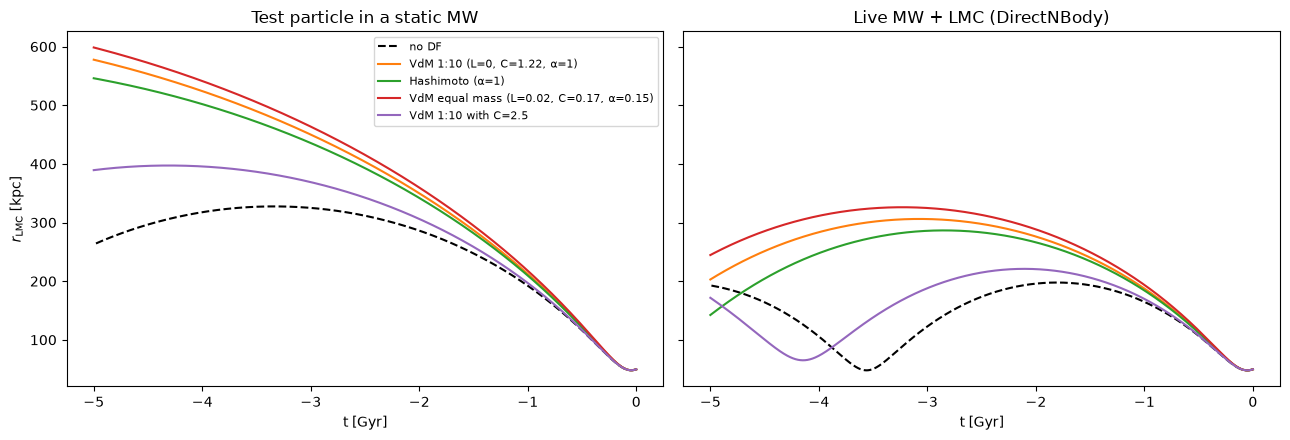

In [15]:
def r_static(orbit):
    return np.linalg.norm(orbit.xyz.to_value(u.kpc), axis=0).squeeze()

def r_live(orbit):
    return np.linalg.norm((orbit.xyz[:, :, 1] - orbit.xyz[:, :, 0]).to_value(u.kpc), axis=0)

t = orbits_static['no DF'].t.to_value(u.Gyr)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for label in configs:
    axes[0].plot(t, r_static(orbits_static[label]), c=colors[label], ls='--' if label == 'no DF' else '-', label=label)
    axes[1].plot(t, r_live(orbits_live[label]), c=colors[label], ls='--' if label == 'no DF' else '-', label=label)
axes[0].set_title('Test particle in a static MW'); axes[1].set_title('Live MW + LMC (DirectNBody)')
for ax in axes:
    ax.set_xlabel('t [Gyr]')
axes[0].set_ylabel(r'$r_{\rm LMC}$ [kpc]'); axes[0].legend(fontsize=8)
fig.tight_layout()

In [16]:
print(f"{'':44s} {'static MW':>26s}   {'live MW + LMC':>26s}")
print(f"{'DF parameters':44s} {'r(-5 Gyr)':>12s} {'max r':>12s}   {'r(-5 Gyr)':>12s} {'max r':>12s}")
for label in configs:
    rs_, rl_ = r_static(orbits_static[label]), r_live(orbits_live[label])
    print(f'{label:44s} {rs_[-1]:10.1f}kpc {rs_.max():10.1f}kpc   {rl_[-1]:10.1f}kpc {rl_.max():10.1f}kpc')

                                                              static MW                live MW + LMC
DF parameters                                   r(-5 Gyr)        max r      r(-5 Gyr)        max r
no DF                                             262.7kpc      327.5kpc        192.8kpc      197.7kpc
VdM 1:10 (L=0, C=1.22, α=1)                       577.7kpc      577.7kpc        202.9kpc      306.1kpc
Hashimoto (α=1)                                   546.0kpc      546.0kpc        142.3kpc      286.6kpc
VdM equal mass (L=0.02, C=0.17, α=0.15)           598.5kpc      598.5kpc        244.6kpc      326.1kpc
VdM 1:10 with C=2.5                               389.3kpc      397.2kpc        171.7kpc      221.0kpc


The right panel of the previous figure uses positions relative to the MW. The MW itself moves in the simulation frame: the initial conditions put
the MW at rest but the LMC in motion, so the barycentre of the pair drifts with
$\mathbf{v}_{\rm cm} = M_{\rm LMC}\mathbf{v}_{\rm LMC}/(M_{\rm MW}+M_{\rm LMC})$, on top of the reflex wobble. Relative quantities don't
depend on this drift, which is why everything is measured relative to the MW particle.

## 5. A test particle in the MW + LMC system: inertial vs. non-inertial frames

In the live run the MW is not at rest: the LMC pulls the MW centre with an acceleration

$$
\mathbf{a}_{\rm MW}(t) = -\nabla\Phi_{\rm LMC}(\mathbf{x}_{\rm MW} - \mathbf{x}_{\rm LMC}).
$$

What does this do to the orbits of stars and satellites *of the MW*? We follow a massless test particle in two frames:

* **Inertial frame** (the simulation frame of Step 4b). The MW and the LMC both move, and the particle feels both potentials
  centred on where they are:
  $$
  \ddot{\mathbf{x}} = -\nabla\Phi_{\rm MW}(\mathbf{x}-\mathbf{x}_{\rm MW}) - \nabla\Phi_{\rm LMC}(\mathbf{x}-\mathbf{x}_{\rm LMC}).
  $$
* **MW (disk) frame**, with coordinates $\mathbf{x}' = \mathbf{x} - \mathbf{x}_{\rm MW}$. The disk stays at the origin, which is
  convenient (this is the frame we observe from), but the frame is **accelerating**, so the equation of motion picks up a
  fictitious force:
  $$
  \ddot{\mathbf{x}}' = -\nabla\Phi_{\rm MW}(\mathbf{x}') - \nabla\Phi_{\rm LMC}(\mathbf{x}'-\mathbf{x}'_{\rm LMC}) \underbrace{-\,\mathbf{a}_{\rm MW}(t)}_{\rm fictitious}.
  $$

A common mistake is to put the MW at the origin and forget the last term. That is the same as nailing the MW in place while the LMC pulls on
everything else. The LMC pull is nearly uniform across the MW, so the fictitious term cancels most of it, and what is left is the
**tidal** (differential) force.

**Setup**

* The particle is massless, so it does not change the MW and LMC orbits. We reuse the live MW + LMC orbits with DF (VdM 1:10) from
  Step 4b and interpolate them in time.
* It starts 4 Gyr ago on a **circular orbit in the X–Z plane** (a polar orbit, perpendicular to the disk) at $r = 50$ kpc around the MW, and we integrate it **forwards** to today, while the
  LMC falls in. The orbit is only exactly circular in a spherical potential; at 50 kpc the disk is a small correction.
* We run four cases: inertial frame, MW frame with the fictitious force, MW frame **without** it, and the MW alone (no LMC) as a reference.

In [17]:
from scipy.interpolate import CubicSpline

# MW and LMC trajectories from the live run with DF, interpolated in time (CubicSpline needs increasing t)
orb_ref = orbits_live['VdM 1:10 (L=0, C=1.22, α=1)']
t_track = orb_ref.t.to_value(u.Myr)[::-1]
xyz_track = orb_ref.xyz.to_value(u.kpc)[:, ::-1]             # (3, n_times, 2): column 0 = MW, column 1 = LMC
vxyz_track = orb_ref.v_xyz.to_value(u.kpc / u.Myr)[:, ::-1]

x_mw_t = CubicSpline(t_track, xyz_track[:, :, 0], axis=1)    # x_MW(t) [kpc], t in Myr
v_mw_t = CubicSpline(t_track, vxyz_track[:, :, 0], axis=1)   # v_MW(t) [kpc/Myr]
x_lmc_t = CubicSpline(t_track, xyz_track[:, :, 1], axis=1)   # x_LMC(t) [kpc]

def a_mw(t):
    # acceleration of the MW centre produced by the LMC [kpc/Myr^2]
    return lmcpot.acceleration((x_mw_t(t) - x_lmc_t(t))[:, None]).decompose(galactic).value[:, 0]

### 5a. The equations of motion in each frame

Both functions have the `F(t, raw_w, *args)` signature from Step 4. `t` is in Myr, so we can evaluate the MW and LMC trajectories directly.

In [18]:
def F_inertial(t, raw_w):
    # both potentials centred on the current MW and LMC positions
    x = raw_w[:3]
    wdot = np.zeros_like(raw_w)
    wdot[:3] = raw_w[3:]
    wdot[3:] = (mwpot.acceleration(x - x_mw_t(t)[:, None]) +
                lmcpot.acceleration(x - x_lmc_t(t)[:, None])).decompose(galactic).value
    return wdot

def F_mwframe(t, raw_w, with_lmc, with_fictitious):
    # MW fixed at the origin; the LMC moves on its orbit relative to the MW
    x = raw_w[:3]
    wdot = np.zeros_like(raw_w)
    wdot[:3] = raw_w[3:]
    wdot[3:] = mwpot.acceleration(x).decompose(galactic).value
    if with_lmc:
        x_lmc_rel = (x_lmc_t(t) - x_mw_t(t))[:, None]
        wdot[3:] += lmcpot.acceleration(x - x_lmc_rel).decompose(galactic).value
        if with_fictitious:
            wdot[3:] -= a_mw(t)[:, None]                         # -a_MW: the frame is accelerating
    return wdot

### 5b. Initial conditions and integration

The particle starts at $\mathbf{x}' = (r, 0, 0)$ with $\mathbf{v}' = (0, 0, v_c(r))$ relative to the MW. In the inertial frame we add
the position and velocity of the MW at $t = -4$ Gyr.

In [19]:
r_circ = 50.0          # kpc, radius of the circular orbit
t_start = -4000.0      # Myr
dt_tp = 1 * u.Myr      # forwards in time
n_steps_tp = 4000      # 4 Gyr

vc_circ = mwpot.circular_velocity([r_circ, 0, 0] * u.kpc)[0].to_value(u.kpc / u.Myr)
x_tp = np.array([r_circ, 0.0, 0.0])
v_tp = np.array([0.0, 0.0, vc_circ])

w0_mwframe = gd.PhaseSpacePosition(pos=x_tp * u.kpc, vel=v_tp * u.kpc / u.Myr)
w0_inertial = gd.PhaseSpacePosition(pos=(x_tp + x_mw_t(t_start)) * u.kpc,
                                    vel=(v_tp + v_mw_t(t_start)) * u.kpc / u.Myr)

runs = {   # label: (F, func_args, w0)
    'inertial frame':                (F_inertial, (), w0_inertial),
    'MW frame + fictitious force':   (F_mwframe, (True, True), w0_mwframe),
    'MW frame, no fictitious force': (F_mwframe, (True, False), w0_mwframe),
    'MW only (no LMC)':              (F_mwframe, (False, False), w0_mwframe),
}

orbits_tp = {}
for label, (F, args, w0) in runs.items():
    integrator = gi.LeapfrogIntegrator(F, func_args=args, func_units=galactic, progress=False)
    orbits_tp[label] = integrator(w0, dt=dt_tp, n_steps=n_steps_tp, t1=t_start * u.Myr)

# positions and velocities relative to the MW centre, so that all four runs can be compared
t_tp = orbits_tp['inertial frame'].t.to_value(u.Myr)
pos_tp, vel_tp = {}, {}
for label, orbit in orbits_tp.items():
    pos_tp[label] = orbit.xyz.to_value(u.kpc).reshape(3, -1)   # (3, n_times)
    vel_tp[label] = orbit.v_xyz.to_value(u.kpc / u.Myr).reshape(3, -1)
    if label == 'inertial frame':
        pos_tp[label] = pos_tp[label] - x_mw_t(t_tp)
        vel_tp[label] = vel_tp[label] - v_mw_t(t_tp)

### 5c. How strong is the MW acceleration?

Compare $|\mathbf{a}_{\rm MW}|$ with the MW's own pull on the particle, $v_c^2/r$. While the LMC is far away the MW acceleration is only
$\sim 1\%$ of $v_c^2/r$, but near pericentre (the last $\sim0.5$ Gyr) it rises to $\sim 20\%$.

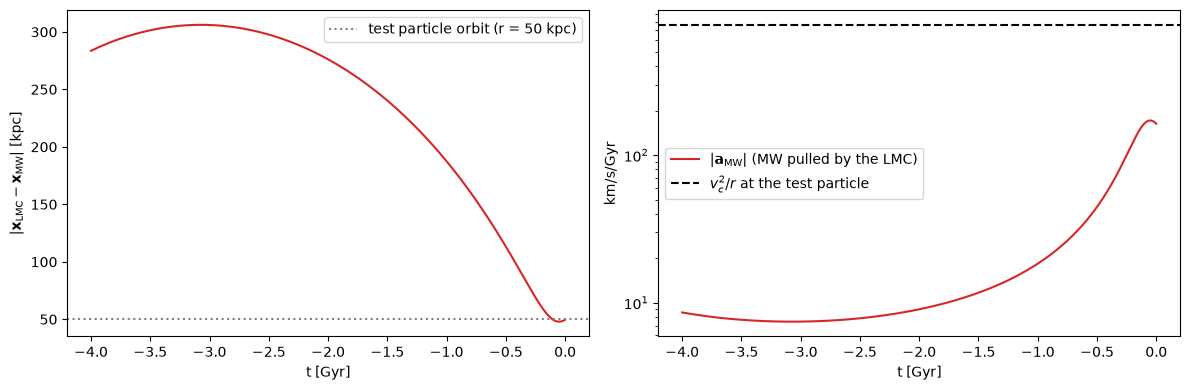

In [20]:
t_gyr = t_tp / 1e3
to_kms_gyr = (1 * u.kpc / u.Myr**2).to_value(u.km / u.s / u.Gyr)
a_mw_tp = np.array([a_mw(ti) for ti in t_tp]).T

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(t_gyr, np.linalg.norm(x_lmc_t(t_tp) - x_mw_t(t_tp), axis=0), c='C3')
axes[0].axhline(r_circ, c='gray', ls=':', label=f'test particle orbit (r = {r_circ:.0f} kpc)')
axes[0].set_ylabel(r'$|\mathbf{x}_{\rm LMC}-\mathbf{x}_{\rm MW}|$ [kpc]'); axes[0].legend()
axes[1].semilogy(t_gyr, np.linalg.norm(a_mw_tp, axis=0) * to_kms_gyr, c='C3', label=r'$|\mathbf{a}_{\rm MW}|$ (MW pulled by the LMC)')
axes[1].axhline(vc_circ**2 / r_circ * to_kms_gyr, c='k', ls='--', label=r'$v_c^2/r$ at the test particle')
axes[1].set_ylabel('km/s/Gyr'); axes[1].legend()
for ax in axes:
    ax.set_xlabel('t [Gyr]')
fig.tight_layout()

### 5d. Comparing the orbits

All orbits are shown relative to the MW centre. The top panels are the orbit seen face-on (X–Z) and edge-on (Y–Z): any motion in $y$ means
the LMC has tilted the orbital plane. The bottom panels show the distance to the MW and how far each run is from the inertial-frame orbit.

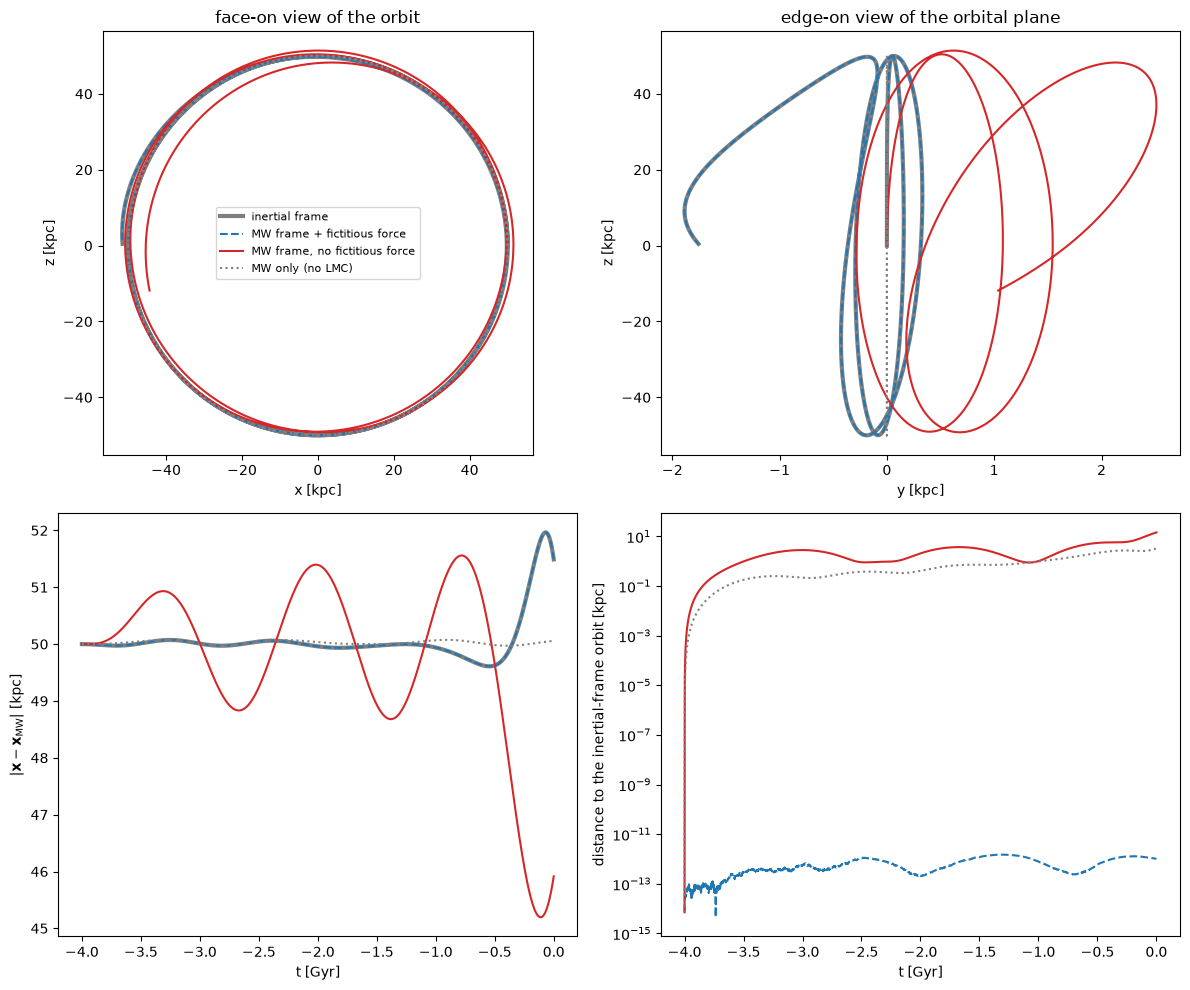

In [21]:
styles = {'inertial frame':                dict(c='k', lw=3, alpha=0.5),
          'MW frame + fictitious force':   dict(c='C0', ls='--'),
          'MW frame, no fictitious force': dict(c='C3'),
          'MW only (no LMC)':              dict(c='gray', ls=':')}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for label in orbits_tp:
    x, y, z = pos_tp[label]
    axes[0, 0].plot(x, z, label=label, **styles[label])
    axes[0, 1].plot(y, z, **styles[label])
    axes[1, 0].plot(t_gyr, np.linalg.norm(pos_tp[label], axis=0), **styles[label])
    if label != 'inertial frame':
        axes[1, 1].semilogy(t_gyr, np.linalg.norm(pos_tp[label] - pos_tp['inertial frame'], axis=0), **styles[label])
axes[0, 0].set_xlabel('x [kpc]'); axes[0, 0].set_ylabel('z [kpc]'); axes[0, 0].set_aspect('equal')
axes[0, 0].set_title('face-on view of the orbit'); axes[0, 0].legend(fontsize=8)
axes[0, 1].set_xlabel('y [kpc]'); axes[0, 1].set_ylabel('z [kpc]'); axes[0, 1].set_title('edge-on view of the orbital plane')
axes[1, 0].set_xlabel('t [Gyr]'); axes[1, 0].set_ylabel(r'$|\mathbf{x}-\mathbf{x}_{\rm MW}|$ [kpc]')
axes[1, 1].set_xlabel('t [Gyr]'); axes[1, 1].set_ylabel('distance to the inertial-frame orbit [kpc]')
fig.tight_layout()

In [22]:
def pole_tilt(pos, vel):
    # angle [deg] between the orbital angular momentum and its initial direction
    L = np.cross(pos.T, vel.T)
    Lhat = L / np.linalg.norm(L, axis=1)[:, None]
    return np.degrees(np.arccos(np.clip(Lhat @ Lhat[0], -1, 1)))

print(f"{'run':32s} {'r today':>10s} {'r min':>8s} {'r max':>8s} {'tilt today':>11s} {'max |Δx| vs inertial':>22s}")
for label in orbits_tp:
    r_ = np.linalg.norm(pos_tp[label], axis=0)
    dx = np.linalg.norm(pos_tp[label] - pos_tp['inertial frame'], axis=0).max()
    print(f'{label:32s} {r_[-1]:8.1f}kpc {r_.min():6.1f}kpc {r_.max():6.1f}kpc '
          f'{pole_tilt(pos_tp[label], vel_tp[label])[-1]:9.1f}deg {dx:18.2e}kpc')

run                                 r today    r min    r max  tilt today   max |Δx| vs inertial
inertial frame                       51.5kpc   49.6kpc   52.0kpc       2.5deg           0.00e+00kpc
MW frame + fictitious force          51.5kpc   49.6kpc   52.0kpc       2.5deg           1.50e-12kpc
MW frame, no fictitious force        45.9kpc   45.2kpc   51.6kpc       4.1deg           1.45e+01kpc
MW only (no LMC)                     50.1kpc   50.0kpc   50.1kpc       0.0deg           3.31e+00kpc


### 5e. What we learn

* **Inertial frame = MW frame + fictitious force.** They are the same equations written in two coordinate systems, and the orbits agree
  to rounding error. Here they even agree step by step, because the MW trajectory was itself computed with a 1 Myr leapfrog.
  Either frame is correct, **as long as the fictitious force is included**.
* **The LMC effect is mostly tidal.** In the correct runs the orbit barely changes while the LMC is far away. Near pericentre the
  particle moves out to $r\approx52$ kpc and its orbital plane tilts by a few degrees.
* **Forgetting the fictitious force overestimates the LMC's effect by several times.** With the MW nailed at the origin, the particle feels the full
  LMC pull instead of only the tidal part. Even 4 Gyr ago, when $|\mathbf{a}_{\rm MW}|$ is only $\sim1\%$ of $v_c^2/r$, this
  uniform push shifts the orbit off-centre and makes the radius oscillate by $\sim 1$ kpc. Near pericentre the error grows to
  $\sim 15$ kpc, and the plane tilt is also too large.
* The opposite way of seeing the same physics: in the inertial frame the inner MW (disk, inner halo) moves together with its centre, while the
  outer halo, where orbital times are long, responds slowly. In the MW frame this shows up as a **reflex motion** of the outer halo
  relative to the disk (Garavito-Camargo et al. 2019, 2021; Petersen & Peñarrubia 2021).

**Try it**

1. Change `r_circ` to 10, 30 and 100 kpc. How does the error from the missing fictitious force scale with radius? (Hint: compare
   $|\mathbf{a}_{\rm MW}|$ with $v_c^2/r$.)
2. Put the particle in the X–Y plane (`v_tp = [0, vc_circ, 0]`) or in the Y–Z plane, close to the LMC orbital plane. Which orientation gets the
   strongest torque from the LMC?
3. Use the LMC orbit without DF (`orbits_live['no DF']`). How much does the pericentre passage, and therefore the perturbation, change?

## References

* Binney & Tremaine 2008, *Galactic Dynamics*, Eq. 8.7
* Hashimoto, Funato & Makino 2003, ApJ, 582, 196
* Zentner & Bullock 2003, ApJ, 598, 49
* Kallivayalil et al. 2013, ApJ, 764, 161
* van der Marel et al. 2012, ApJ, 753, 9
* Patel, Besla & Sohn 2017, MNRAS, 464, 3825; Patel et al. 2020, ApJ, 893, 121
* Garavito-Camargo et al. 2019, ApJ, 884, 51; Garavito-Camargo et al. 2021, ApJ, 919, 109
* Petersen & Peñarrubia 2021, Nature Astronomy, 5, 251
* `gala` docs: [integration with custom functions](https://gala.adrian.pw/en/latest/integrate/index.html), [`DirectNBody`](https://gala.adrian.pw/en/latest/dynamics/nbody.html)